# COVID-19 Data Analysis

## Objective

Analyze COVID-19 case progression using historical global data to understand trends in confirmed cases, recoveries, and deaths. The analysis includes data cleaning, daily trend analysis, visualization, and trend-line analysis.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [6]:
df = pd.read_csv("../data/covid_19_clean_complete.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (49068, 10)


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.94,67.71,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15,20.17,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03,1.66,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.51,1.52,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20,17.87,2020-01-22,0,0,0,0,Africa


In [7]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'WHO Region']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  str    
 1   Country/Region  49068 non-null  str    
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  str    
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  str    
dtypes: float64(2), int64(4), str(4)
memory usage: 3.7 MB


In [9]:
df.describe()

,Lat,Long,Confirmed,Deaths,Recovered,Active
count,49068.00,49068.00,49068.00,49068.00,49068.00,49068.00
mean,21.43,23.53,16884.90,884.18,7915.71,8085.01
std,24.95,70.44,127300.21,6313.58,54800.92,76258.90
min,-51.80,-135.00,0.00,0.00,0.00,-14.00
25%,7.87,-15.31,4.00,0.00,0.00,0.00
50%,23.63,21.75,168.00,2.00,29.00,26.00
75%,41.20,80.77,1518.25,30.00,666.00,606.00
max,71.71,178.06,4290259.00,148011.00,1846641.00,2816444.00


In [10]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
print(df.columns.tolist())

['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'WHO Region']


In [13]:
df["Date"] = pd.to_datetime(df["Date"])

In [14]:
print("Date range:")
print(df["Date"].min(), "to", df["Date"].max())

Date range:
2020-01-22 00:00:00 to 2020-07-27 00:00:00


In [15]:
metric_columns = ["Confirmed", "Deaths", "Recovered"]

print("Negative values:")
print((df[metric_columns] < 0).sum())

Negative values:
Confirmed    0
Deaths       0
Recovered    0
dtype: int64


In [16]:
print("Missing values in COVID metrics:")
print(df[metric_columns].isnull().sum())

Missing values in COVID metrics:
Confirmed    0
Deaths       0
Recovered    0
dtype: int64


In [17]:
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["Date"].min(), df["Date"].max())

(49068, 10)
['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'WHO Region']
Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64
0
2020-01-22 00:00:00 2020-07-27 00:00:00


In [18]:
print((df[metric_columns] < 0).sum())

Confirmed    0
Deaths       0
Recovered    0
dtype: int64


In [19]:
# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Sort data by date
df = df.sort_values("Date").reset_index(drop=True)

# Check data types after cleaning
print(df.dtypes)

Province/State               str
Country/Region               str
Lat                      float64
Long                     float64
Date              datetime64[us]
Confirmed                  int64
Deaths                     int64
Recovered                  int64
Active                     int64
WHO Region                   str
dtype: object


In [20]:
print("Number of unique countries/regions:", df["Country/Region"].nunique())

print("\nCountries/Regions:")
print(df["Country/Region"].unique()[:20])

Number of unique countries/regions: 187

Countries/Regions:
<StringArray>
[     'Afghanistan',      'Netherlands',      'New Zealand',
        'Nicaragua',            'Niger',          'Nigeria',
  'North Macedonia',           'Norway',             'Oman',
         'Pakistan',           'Panama', 'Papua New Guinea',
         'Paraguay',             'Peru',           'Poland',
         'Portugal',            'Qatar',          'Romania',
           'Russia',           'Rwanda']
Length: 20, dtype: str


In [21]:
print("Number of records per country:")
print(df["Country/Region"].value_counts().head(10))

Number of records per country:
Country/Region
China             6204
Canada            2256
United Kingdom    2068
France            2068
Australia         1504
Netherlands        752
Denmark            376
Afghanistan        188
New Zealand        188
Nicaragua          188
Name: count, dtype: int64


In [22]:
daily_global = (
    df.groupby("Date")[["Confirmed", "Deaths", "Recovered", "Active"]]
      .sum()
      .reset_index()
)

daily_global.head()

,Date,Confirmed,Deaths,Recovered,Active
0,2020-01-22,555,17,28,510
1,2020-01-23,654,18,30,606
2,2020-01-24,941,26,36,879
3,2020-01-25,1434,42,39,1353
4,2020-01-26,2118,56,52,2010


In [23]:
print("Global daily dataset shape:", daily_global.shape)

print("\nDate range:")
print(daily_global["Date"].min(), "to", daily_global["Date"].max())

daily_global.tail()

Global daily dataset shape: (188, 5)

Date range:
2020-01-22 00:00:00 to 2020-07-27 00:00:00


,Date,Confirmed,Deaths,Recovered,Active
183,2020-07-23,15510481,633506,8710969,6166006
184,2020-07-24,15791645,639650,8939705,6212290
185,2020-07-25,16047190,644517,9158743,6243930
186,2020-07-26,16251796,648621,9293464,6309711
187,2020-07-27,16480485,654036,9468087,6358362


In [24]:
daily_global["New Cases"] = daily_global["Confirmed"].diff().fillna(0)
daily_global["New Deaths"] = daily_global["Deaths"].diff().fillna(0)
daily_global["New Recovered"] = daily_global["Recovered"].diff().fillna(0)

daily_global.head()

,Date,Confirmed,Deaths,Recovered,Active,New Cases,New Deaths,New Recovered
0,2020-01-22,555,17,28,510,0.00,0.00,0.00
1,2020-01-23,654,18,30,606,99.00,1.00,2.00
2,2020-01-24,941,26,36,879,287.00,8.00,6.00
3,2020-01-25,1434,42,39,1353,493.00,16.00,3.00
4,2020-01-26,2118,56,52,2010,684.00,14.00,13.00


In [25]:
print(
    daily_global[
        ["Date", "New Cases", "New Deaths", "New Recovered"]
    ].head(10)
)

        Date  New Cases  New Deaths  New Recovered
0 2020-01-22       0.00        0.00           0.00
1 2020-01-23      99.00        1.00           2.00
2 2020-01-24     287.00        8.00           6.00
3 2020-01-25     493.00       16.00           3.00
4 2020-01-26     684.00       14.00          13.00
5 2020-01-27     809.00       26.00           9.00
6 2020-01-28    2651.00       49.00          46.00
7 2020-01-29     588.00        2.00          18.00
8 2020-01-30    2068.00       38.00          16.00
9 2020-01-31    1693.00       42.00          78.00


In [26]:
print("Negative daily cases:", (daily_global["New Cases"] < 0).sum())
print("Negative daily deaths:", (daily_global["New Deaths"] < 0).sum())
print("Negative daily recoveries:", (daily_global["New Recovered"] < 0).sum())

Negative daily cases: 0
Negative daily deaths: 0
Negative daily recoveries: 0


In [27]:
print(daily_global.shape)
print(daily_global.tail())

(188, 8)
          Date  Confirmed  Deaths  Recovered   Active  New Cases  New Deaths  \
183 2020-07-23   15510481  633506    8710969  6166006  282756.00     9966.00   
184 2020-07-24   15791645  639650    8939705  6212290  281164.00     6144.00   
185 2020-07-25   16047190  644517    9158743  6243930  255545.00     4867.00   
186 2020-07-26   16251796  648621    9293464  6309711  204606.00     4104.00   
187 2020-07-27   16480485  654036    9468087  6358362  228689.00     5415.00   

     New Recovered  
183      169714.00  
184      228736.00  
185      219038.00  
186      134721.00  
187      174623.00  


In [28]:
print("Negative daily cases:", (daily_global["New Cases"] < 0).sum())
print("Negative daily deaths:", (daily_global["New Deaths"] < 0).sum())
print("Negative daily recoveries:", (daily_global["New Recovered"] < 0).sum())

Negative daily cases: 0
Negative daily deaths: 0
Negative daily recoveries: 0


In [40]:
# Peak daily statistics

peak_cases = daily_global.loc[daily_global["New Cases"].idxmax()]
peak_deaths = daily_global.loc[daily_global["New Deaths"].idxmax()]
peak_recoveries = daily_global.loc[daily_global["New Recovered"].idxmax()]

print("Peak Daily COVID-19 Statistics")
print("-" * 40)

print(f"Peak New Cases: {peak_cases['New Cases']:,.0f}")
print(f"Date: {peak_cases['Date'].date()}")

print(f"\nPeak New Deaths: {peak_deaths['New Deaths']:,.0f}")
print(f"Date: {peak_deaths['Date'].date()}")

print(f"\nPeak New Recoveries: {peak_recoveries['New Recovered']:,.0f}")
print(f"Date: {peak_recoveries['Date'].date()}")

Peak Daily COVID-19 Statistics
----------------------------------------
Peak New Cases: 282,756
Date: 2020-07-23

Peak New Deaths: 9,966
Date: 2020-07-23

Peak New Recoveries: 284,394
Date: 2020-07-02


In [30]:
print("Final Global Totals")
print("-------------------")
print("Confirmed:", f"{daily_global['Confirmed'].iloc[-1]:,}")
print("Deaths:", f"{daily_global['Deaths'].iloc[-1]:,}")
print("Recovered:", f"{daily_global['Recovered'].iloc[-1]:,}")
print("Active:", f"{daily_global['Active'].iloc[-1]:,}")

Final Global Totals
-------------------
Confirmed: 16,480,485
Deaths: 654,036
Recovered: 9,468,087
Active: 6,358,362


In [31]:
import os

os.makedirs("../visuals", exist_ok=True)

print("Visuals folder ready.")

Visuals folder ready.


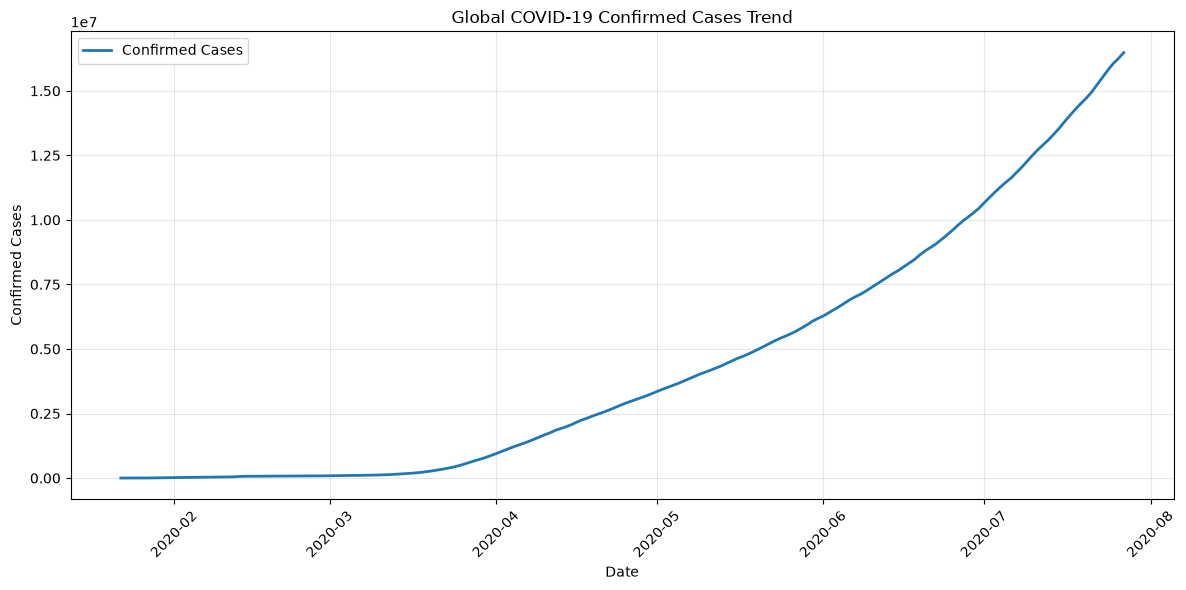

In [32]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_global["Date"],
    daily_global["Confirmed"],
    linewidth=2,
    label="Confirmed Cases"
)

plt.title("Global COVID-19 Confirmed Cases Trend")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("../visuals/confirmed_cases_trend.png", dpi=300)
plt.show()

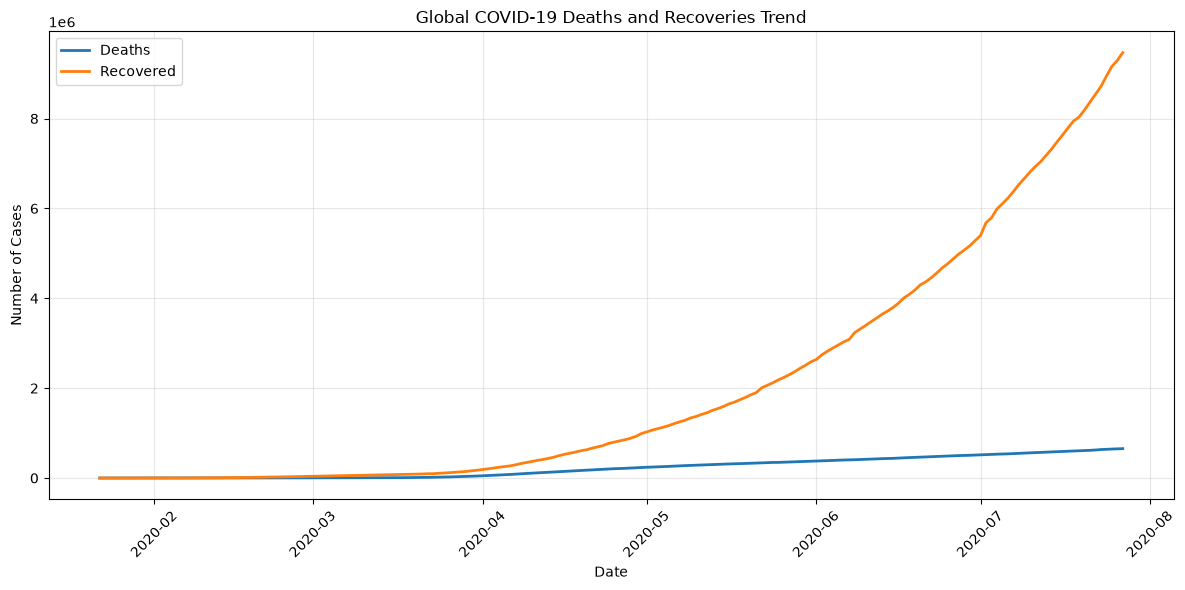

In [33]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_global["Date"],
    daily_global["Deaths"],
    linewidth=2,
    label="Deaths"
)

plt.plot(
    daily_global["Date"],
    daily_global["Recovered"],
    linewidth=2,
    label="Recovered"
)

plt.title("Global COVID-19 Deaths and Recoveries Trend")
plt.xlabel("Date")
plt.ylabel("Number of Cases")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("../visuals/deaths_recoveries_trend.png", dpi=300)
plt.show()

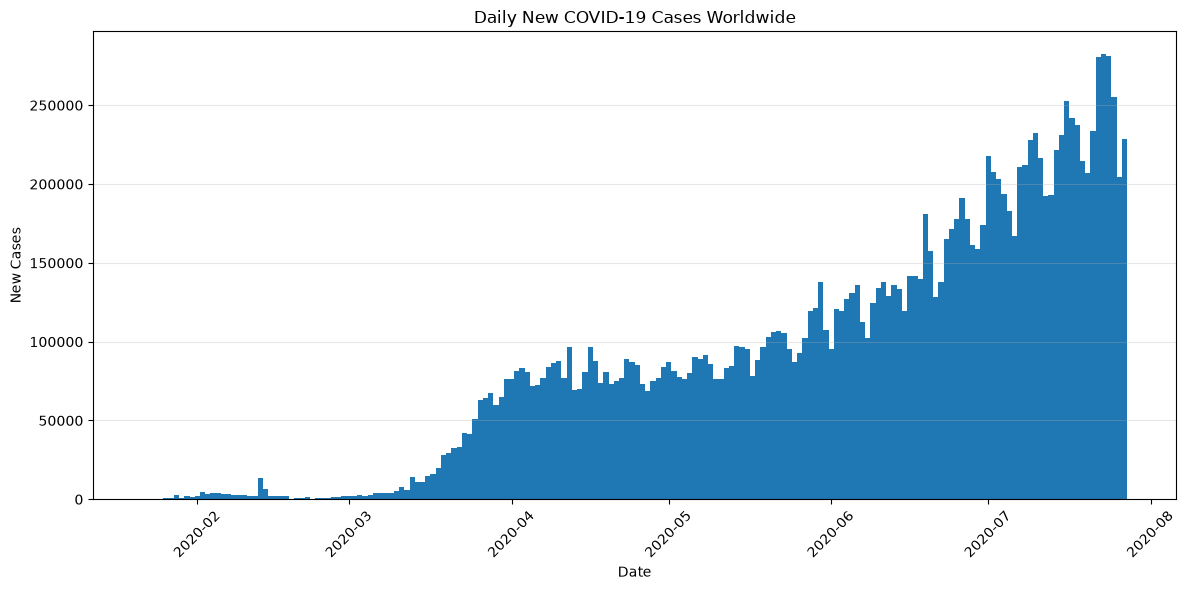

In [34]:
plt.figure(figsize=(12, 6))

plt.bar(
    daily_global["Date"],
    daily_global["New Cases"],
    width=1.0
)

plt.title("Daily New COVID-19 Cases Worldwide")
plt.xlabel("Date")
plt.ylabel("New Cases")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../visuals/daily_new_cases.png", dpi=300)
plt.show()

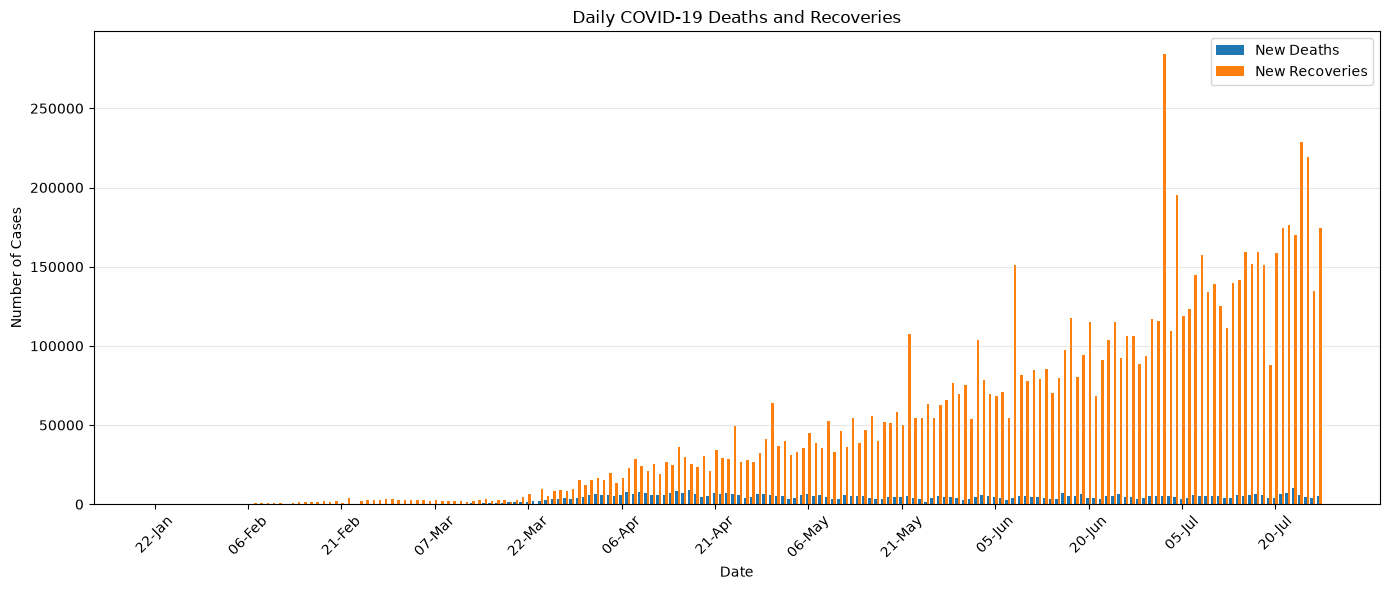

In [35]:
x = np.arange(len(daily_global))
width = 0.4

plt.figure(figsize=(14, 6))

plt.bar(
    x - width / 2,
    daily_global["New Deaths"],
    width,
    label="New Deaths"
)

plt.bar(
    x + width / 2,
    daily_global["New Recovered"],
    width,
    label="New Recoveries"
)

plt.title("Daily COVID-19 Deaths and Recoveries")
plt.xlabel("Date")
plt.ylabel("Number of Cases")

# Show fewer date labels for readability
step = 15
plt.xticks(
    x[::step],
    daily_global["Date"].dt.strftime("%d-%b")[::step],
    rotation=45
)

plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("../visuals/daily_deaths_recoveries.png", dpi=300)
plt.show()

In [36]:
# Prepare data for trend-line calculation
x = np.arange(len(daily_global))
y = daily_global["Confirmed"]

# Calculate linear trend
slope, intercept = np.polyfit(x, y, 1)

# Generate trend-line values
trend_line = slope * x + intercept

# Display equation
print("Trend Line Equation:")
print(f"Confirmed Cases = {slope:.2f} × Day + {intercept:.2f}")

Trend Line Equation:
Confirmed Cases = 81754.35 × Day + -3237072.13


In [37]:
summary = pd.DataFrame({
    "Metric": [
        "Total Confirmed Cases",
        "Total Deaths",
        "Total Recovered",
        "Total Active Cases",
        "Peak Daily New Cases",
        "Peak Daily New Deaths",
        "Peak Daily New Recoveries"
    ],
    "Value": [
        daily_global["Confirmed"].iloc[-1],
        daily_global["Deaths"].iloc[-1],
        daily_global["Recovered"].iloc[-1],
        daily_global["Active"].iloc[-1],
        daily_global["New Cases"].max(),
        daily_global["New Deaths"].max(),
        daily_global["New Recovered"].max()
    ]
})

summary

,Metric,Value
0,Total Confirmed Cases,16480485.00
1,Total Deaths,654036.00
2,Total Recovered,9468087.00
3,Total Active Cases,6358362.00
4,Peak Daily New Cases,282756.00
5,Peak Daily New Deaths,9966.00
6,Peak Daily New Recoveries,284394.00


In [38]:
daily_global.to_csv(
    "../data/global_daily_covid_analysis.csv",
    index=False
)

print("Processed dataset saved successfully.")

Processed dataset saved successfully.


Trend-line chart saved successfully.
Trend Line Equation: Confirmed Cases = 81754.35 × Day + -3237072.13


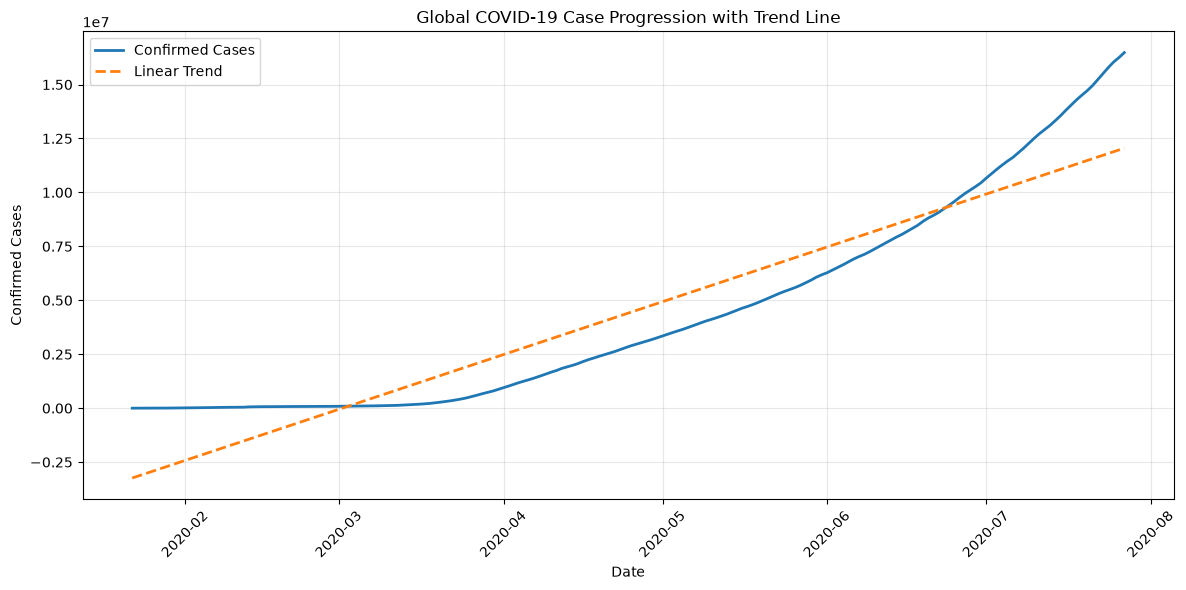

In [39]:
# Calculate linear trend line
x = np.arange(len(daily_global))
y = daily_global["Confirmed"]

slope, intercept = np.polyfit(x, y, 1)
trend_line = slope * x + intercept

# Plot confirmed cases and trend line
plt.figure(figsize=(12, 6))

plt.plot(
    daily_global["Date"],
    daily_global["Confirmed"],
    linewidth=2,
    label="Confirmed Cases"
)

plt.plot(
    daily_global["Date"],
    trend_line,
    linestyle="--",
    linewidth=2,
    label="Linear Trend"
)

plt.title("Global COVID-19 Case Progression with Trend Line")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# Save the figure
plt.savefig("../visuals/confirmed_cases_trend_line.png", dpi=300)

print("Trend-line chart saved successfully.")
print(f"Trend Line Equation: Confirmed Cases = {slope:.2f} × Day + {intercept:.2f}")

plt.show()